<a href="https://colab.research.google.com/github/nharri64/ECGR-4105/blob/Homeworks-and-datasets/Noah_Harris_801353171_HW5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import torch
import numpy as np
import matplotlib.pyplot as plt

# Temperature data from Lecture 8
t_c = torch.tensor([
    0.5, 14.0, 15.0, 28.0, 11.0, 8.0,
    3.0, -4.0, 6.0, 13.0, 21.0
], dtype=torch.float32)

t_u = torch.tensor([
    35.7, 55.9, 58.2, 81.9, 56.3, 48.9,
    33.9, 21.8, 48.4, 60.4, 68.4
], dtype=torch.float32)

print("Number of temperature samples:", len(t_u))
print("Input measurements:", t_u)
print("Actual temperatures:", t_c)


Number of temperature samples: 11
Input measurements: tensor([35.7000, 55.9000, 58.2000, 81.9000, 56.3000, 48.9000, 33.9000, 21.8000,
        48.4000, 60.4000, 68.4000])
Actual temperatures: tensor([ 0.5000, 14.0000, 15.0000, 28.0000, 11.0000,  8.0000,  3.0000, -4.0000,
         6.0000, 13.0000, 21.0000])


In [2]:

# Nonlinear temperature prediction model
def nonlinear_model(t_u, w2, w1, b):
    return w2 * t_u**2 + w1 * t_u + b

# Original linear model for comparison
def linear_model(t_u, w, b):
    return w * t_u + b

# Mean Squared Error loss
def loss_fn(predicted, actual):
    return ((predicted - actual)**2).mean()

print("Linear and nonlinear models defined.")


Linear and nonlinear models defined.


In [3]:

def train_temperature(model, initial_params, learning_rate,
                      inputs, targets, epochs=5000):

    params = torch.tensor(
        initial_params,
        dtype=torch.float32,
        requires_grad=True
    )

    optimizer = torch.optim.SGD([params], lr=learning_rate)
    history = []

    for epoch in range(1, epochs + 1):
        predictions = model(inputs, *params)
        loss = loss_fn(predictions, targets)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        with torch.no_grad():
            current_loss = loss_fn(
                model(inputs, *params), targets
            ).item()

        history.append(current_loss)

        if epoch % 500 == 0:
            print(
                f"Epoch {epoch}: "
                f"Loss = {current_loss:.6f}"
            )

    return params.detach().clone(), history

print("Training loop ready.")


Training loop ready.


In [4]:

# Scale temperature inputs for stable training
t_u_scaled = t_u / 100.0

print("Scaled temperature inputs:")
print(t_u_scaled)


Scaled temperature inputs:
tensor([0.3570, 0.5590, 0.5820, 0.8190, 0.5630, 0.4890, 0.3390, 0.2180, 0.4840,
        0.6040, 0.6840])


In [5]:

learning_rates = [0.1, 0.01, 0.001, 0.0001]

nonlinear_results = {}

for lr in learning_rates:
    print(f"\nLearning Rate: {lr}")
    print("----------------------")

    params, history = train_temperature(
        model=nonlinear_model,
        initial_params=[0.0, 0.0, 0.0],
        learning_rate=lr,
        inputs=t_u_scaled,
        targets=t_c,
        epochs=5000
    )

    nonlinear_results[lr] = {
        "params": params,
        "history": history,
        "final_loss": history[-1]
    }

print("\nFinal Loss Comparison")
for lr, result in nonlinear_results.items():
    print(f"LR {lr}: {result['final_loss']:.6f}")

best_lr = min(
    nonlinear_results,
    key=lambda lr: nonlinear_results[lr]["final_loss"]
)

print("\nBest Learning Rate:", best_lr)
print("Best Parameters:", nonlinear_results[best_lr]["params"])
print("Best Final Loss:", nonlinear_results[best_lr]["final_loss"])



Learning Rate: 0.1
----------------------
Epoch 500: Loss = 2.109356
Epoch 1000: Loss = 2.090731
Epoch 1500: Loss = 2.090725
Epoch 2000: Loss = 2.090723
Epoch 2500: Loss = 2.090724
Epoch 3000: Loss = 2.090723
Epoch 3500: Loss = 2.090723
Epoch 4000: Loss = 2.090723
Epoch 4500: Loss = 2.090723
Epoch 5000: Loss = 2.090722

Learning Rate: 0.01
----------------------
Epoch 500: Loss = 27.857922
Epoch 1000: Loss = 13.664641
Epoch 1500: Loss = 7.289416
Epoch 2000: Loss = 4.425832
Epoch 2500: Loss = 3.139586
Epoch 3000: Loss = 2.561845
Epoch 3500: Loss = 2.302338
Epoch 4000: Loss = 2.185778
Epoch 4500: Loss = 2.133420
Epoch 5000: Loss = 2.109904

Learning Rate: 0.001
----------------------
Epoch 500: Loss = 63.308411
Epoch 1000: Loss = 51.507801
Epoch 1500: Loss = 47.250000
Epoch 2000: Loss = 43.748131
Epoch 2500: Loss = 40.543205
Epoch 3000: Loss = 37.586502
Epoch 3500: Loss = 34.857250
Epoch 4000: Loss = 32.337856
Epoch 4500: Loss = 30.012182
Epoch 5000: Loss = 27.865314

Learning Rate: 0.0

In [6]:

# Problem 1c - Train linear model for comparison

print("Training Linear Model")

linear_params, linear_history = train_temperature(
    model=linear_model,
    initial_params=[1.0, 0.0],
    learning_rate=0.1,
    inputs=t_u_scaled,
    targets=t_c,
    epochs=5000
)

print("\nFinal Linear Model Parameters:", linear_params)
print("Final Linear Model Loss:", linear_history[-1])

print("\nBest Nonlinear Model Loss:",
      nonlinear_results[best_lr]["final_loss"])


Training Linear Model
Epoch 500: Loss = 3.977957
Epoch 1000: Loss = 2.945907
Epoch 1500: Loss = 2.927963
Epoch 2000: Loss = 2.927651
Epoch 2500: Loss = 2.927646
Epoch 3000: Loss = 2.927645
Epoch 3500: Loss = 2.927645
Epoch 4000: Loss = 2.927645
Epoch 4500: Loss = 2.927645
Epoch 5000: Loss = 2.927645

Final Linear Model Parameters: tensor([ 53.6767, -17.3045])
Final Linear Model Loss: 2.927644968032837

Best Nonlinear Model Loss: 2.090721607208252


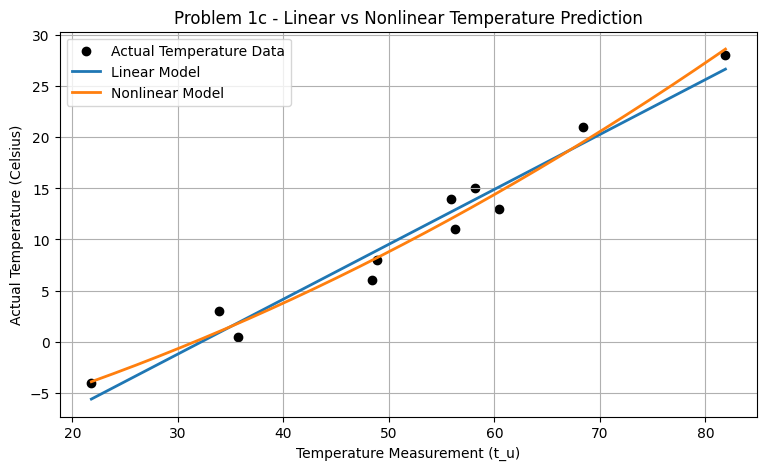

In [7]:

# Problem 1c - Compare linear and nonlinear predictions

best_nonlinear_params = nonlinear_results[best_lr]["params"]

# Smooth input values for drawing the curves
x_plot = torch.linspace(
    t_u_scaled.min().item(),
    t_u_scaled.max().item(),
    200
)

with torch.no_grad():
    linear_predictions = linear_model(
        x_plot, *linear_params
    )

    nonlinear_predictions = nonlinear_model(
        x_plot, *best_nonlinear_params
    )

plt.figure(figsize=(9, 5))

# Original temperature data
plt.scatter(
    t_u.numpy(),
    t_c.numpy(),
    color="black",
    label="Actual Temperature Data"
)

# Linear predictions
plt.plot(
    (x_plot * 100).numpy(),
    linear_predictions.numpy(),
    label="Linear Model",
    linewidth=2
)

# Nonlinear predictions
plt.plot(
    (x_plot * 100).numpy(),
    nonlinear_predictions.numpy(),
    label="Nonlinear Model",
    linewidth=2
)

plt.xlabel("Temperature Measurement (t_u)")
plt.ylabel("Actual Temperature (Celsius)")
plt.title("Problem 1c - Linear vs Nonlinear Temperature Prediction")
plt.legend()
plt.grid(True)
plt.show()


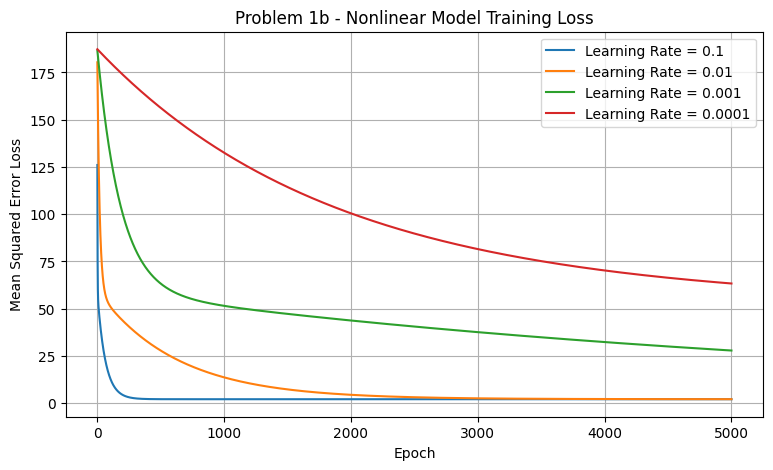

In [8]:

# Problem 1b - Loss comparison across learning rates

plt.figure(figsize=(9, 5))

for lr, result in nonlinear_results.items():
    plt.plot(
        range(1, 5001),
        result["history"],
        label=f"Learning Rate = {lr}"
    )

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error Loss")
plt.title("Problem 1b - Nonlinear Model Training Loss")
plt.legend()
plt.grid(True)
plt.show()


In [9]:

# Problem 1 - Final comparison

linear_loss = linear_history[-1]
nonlinear_loss = nonlinear_results[best_lr]["final_loss"]

print("Problem 1 - Final Results")
print("-------------------------")
print(f"Linear Model Loss: {linear_loss:.6f}")
print(f"Nonlinear Model Loss: {nonlinear_loss:.6f}")

if nonlinear_loss < linear_loss:
    print("The nonlinear model performed better.")
elif nonlinear_loss > linear_loss:
    print("The linear model performed better.")
else:
    print("Both models had the same loss.")


Problem 1 - Final Results
-------------------------
Linear Model Loss: 2.927645
Nonlinear Model Loss: 2.090722
The nonlinear model performed better.


In [11]:

# Problem 2 - Upload housing dataset

from google.colab import files

uploaded = files.upload()


Saving Housing.csv to Housing.csv


In [12]:

# Problem 2 - Load housing dataset

import pandas as pd
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

housing = pd.read_csv("Housing.csv")

print("Dataset shape:", housing.shape)
print(housing.head())
print(housing.isnull().sum())


Dataset shape: (545, 13)
      price  area  bedrooms  bathrooms  stories mainroad guestroom basement  \
0  13300000  7420         4          2        3      yes        no       no   
1  12250000  8960         4          4        4      yes        no       no   
2  12250000  9960         3          2        2      yes        no      yes   
3  12215000  7500         4          2        2      yes        no      yes   
4  11410000  7420         4          1        2      yes       yes      yes   

  hotwaterheating airconditioning  parking prefarea furnishingstatus  
0              no             yes        2      yes        furnished  
1              no             yes        3       no        furnished  
2              no              no        2      yes   semi-furnished  
3              no             yes        3      yes        furnished  
4              no             yes        2       no        furnished  
price               0
area                0
bedrooms            0
bathroom

In [13]:

# Problem 2a - Select the five input features

features_2 = [
    "area",
    "bedrooms",
    "bathrooms",
    "stories",
    "parking"
]

X_2 = housing[features_2]
y_2 = housing["price"]

print("Features:", features_2)
print("Number of features:", X_2.shape[1])
print("Total samples:", len(X_2))


Features: ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
Number of features: 5
Total samples: 545


In [14]:

# Problem 2a - Training and validation data

X_train_2, X_val_2, y_train_2, y_val_2 = train_test_split(
    X_2,
    y_2,
    test_size=0.20,
    random_state=42
)

scaler_2 = StandardScaler()

X_train_scaled_2 = scaler_2.fit_transform(X_train_2)
X_val_scaled_2 = scaler_2.transform(X_val_2)

# Prices are represented in millions during training
y_train_scaled_2 = y_train_2.to_numpy() / 1_000_000
y_val_scaled_2 = y_val_2.to_numpy() / 1_000_000

X_train_tensor_2 = torch.tensor(
    X_train_scaled_2, dtype=torch.float32
)

X_val_tensor_2 = torch.tensor(
    X_val_scaled_2, dtype=torch.float32
)

y_train_tensor_2 = torch.tensor(
    y_train_scaled_2, dtype=torch.float32
).reshape(-1, 1)

y_val_tensor_2 = torch.tensor(
    y_val_scaled_2, dtype=torch.float32
).reshape(-1, 1)

print("Training samples:", len(X_train_tensor_2))
print("Validation samples:", len(X_val_tensor_2))


Training samples: 436
Validation samples: 109


In [15]:

# Problem 2a - Linear regression model

def create_housing_model(num_features):
    model = nn.Linear(num_features, 1)

    with torch.no_grad():
        model.weight.zero_()
        model.bias.zero_()

    return model

model_test_2 = create_housing_model(5)

print(model_test_2)
print(
    "Number of parameters:",
    sum(p.numel() for p in model_test_2.parameters())
)


Linear(in_features=5, out_features=1, bias=True)
Number of parameters: 6


In [16]:

# Problem 2b - Training loop

def train_housing_model(
    num_features,
    X_train, y_train,
    X_val, y_val,
    learning_rate,
    epochs=5000
):
    model = create_housing_model(num_features)

    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=learning_rate
    )

    loss_fn_housing = nn.MSELoss()

    train_losses = []
    val_losses = []
    val_r2_scores = []

    for epoch in range(1, epochs + 1):

        model.train()

        predictions = model(X_train)
        train_loss = loss_fn_housing(predictions, y_train)

        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()

        model.eval()

        with torch.no_grad():
            train_pred = model(X_train)
            val_pred = model(X_val)

            current_train_loss = loss_fn_housing(
                train_pred, y_train
            ).item()

            current_val_loss = loss_fn_housing(
                val_pred, y_val
            ).item()

            current_r2 = r2_score(
                y_val.numpy(),
                val_pred.numpy()
            )

        train_losses.append(current_train_loss)
        val_losses.append(current_val_loss)
        val_r2_scores.append(current_r2)

        if epoch % 500 == 0:
            print(
                f"Epoch {epoch}: "
                f"Train Loss = {current_train_loss:.6f}, "
                f"Val Loss = {current_val_loss:.6f}, "
                f"Val R2 = {current_r2:.4f}"
            )

    return {
        "model": model,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "val_r2_scores": val_r2_scores
    }

print("Training loop ready.")


Training loop ready.


In [17]:

# Problem 2b - Train four models

learning_rates_2 = [0.1, 0.01, 0.001, 0.0001]

results_2 = {}

for lr in learning_rates_2:
    print(f"\nLearning Rate: {lr}")
    print("-------------------------")

    result = train_housing_model(
        num_features=5,
        X_train=X_train_tensor_2,
        y_train=y_train_tensor_2,
        X_val=X_val_tensor_2,
        y_val=y_val_tensor_2,
        learning_rate=lr,
        epochs=5000
    )

    results_2[lr] = result

print("\nFinal Results Comparison")

for lr, result in results_2.items():
    print(
        f"LR {lr}: "
        f"Train Loss = {result['train_losses'][-1]:.6f}, "
        f"Val Loss = {result['val_losses'][-1]:.6f}, "
        f"Val R2 = {result['val_r2_scores'][-1]:.4f}"
    )

best_lr_2 = min(
    results_2,
    key=lambda lr: results_2[lr]["val_losses"][-1]
)

print("\nBest Learning Rate:", best_lr_2)
print(
    "Best Validation Loss:",
    results_2[best_lr_2]["val_losses"][-1]
)



Learning Rate: 0.1
-------------------------
Epoch 500: Train Loss = 1.350008, Val Loss = 2.292722, Val R2 = 0.5464
Epoch 1000: Train Loss = 1.350008, Val Loss = 2.292722, Val R2 = 0.5464
Epoch 1500: Train Loss = 1.350008, Val Loss = 2.292722, Val R2 = 0.5464
Epoch 2000: Train Loss = 1.350008, Val Loss = 2.292722, Val R2 = 0.5464
Epoch 2500: Train Loss = 1.350008, Val Loss = 2.292722, Val R2 = 0.5464
Epoch 3000: Train Loss = 1.350008, Val Loss = 2.292722, Val R2 = 0.5464
Epoch 3500: Train Loss = 1.350008, Val Loss = 2.292722, Val R2 = 0.5464
Epoch 4000: Train Loss = 1.350008, Val Loss = 2.292722, Val R2 = 0.5464
Epoch 4500: Train Loss = 1.350008, Val Loss = 2.292722, Val R2 = 0.5464
Epoch 5000: Train Loss = 1.350008, Val Loss = 2.292722, Val R2 = 0.5464

Learning Rate: 0.01
-------------------------
Epoch 500: Train Loss = 1.350009, Val Loss = 2.292813, Val R2 = 0.5464
Epoch 1000: Train Loss = 1.350008, Val Loss = 2.292725, Val R2 = 0.5464
Epoch 1500: Train Loss = 1.350008, Val Loss =

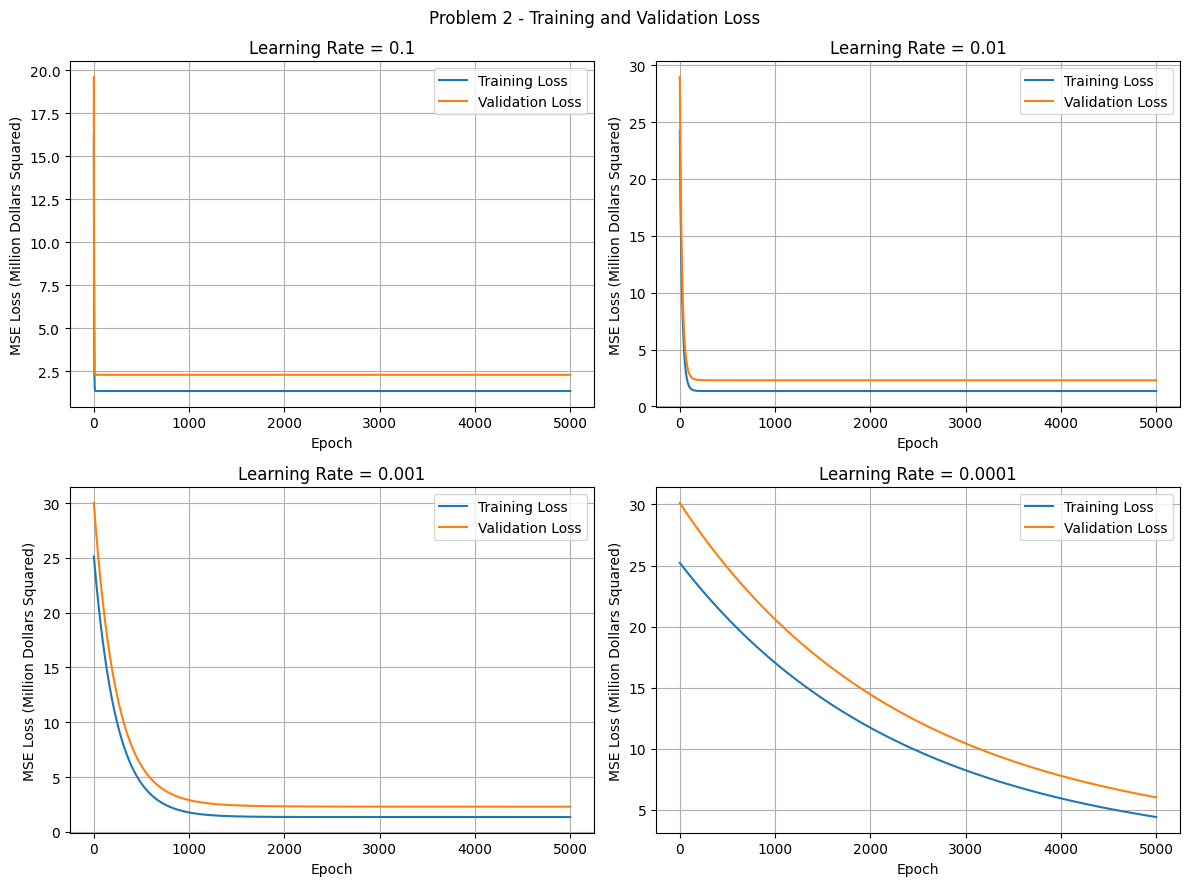

In [18]:

# Problem 2b - Training and validation loss graphs

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (lr, result) in zip(axes.flat, results_2.items()):
    ax.plot(
        range(1, 5001),
        result["train_losses"],
        label="Training Loss"
    )

    ax.plot(
        range(1, 5001),
        result["val_losses"],
        label="Validation Loss"
    )

    ax.set_title(f"Learning Rate = {lr}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE Loss (Million Dollars Squared)")
    ax.legend()
    ax.grid(True)

plt.suptitle("Problem 2 - Training and Validation Loss")
plt.tight_layout()
plt.show()


In [19]:

# Problem 2a - Best six parameters

best_model_2 = results_2[best_lr_2]["model"]

weights_2 = best_model_2.weight.detach().numpy().flatten()
bias_2 = best_model_2.bias.detach().item()

print("Best Learning Rate:", best_lr_2)

for feature, weight in zip(features_2, weights_2):
    print(f"{feature}: {weight:.6f}")

print(f"Bias: {bias_2:.6f}")

print(
    "\nFinal Validation Loss:",
    results_2[best_lr_2]["val_losses"][-1]
)

print(
    "Final Validation R2:",
    results_2[best_lr_2]["val_r2_scores"][-1]
)


Best Learning Rate: 0.1
area: 0.680058
bedrooms: 0.112973
bathrooms: 0.565408
stories: 0.424355
parking: 0.288349
Bias: 4.706527

Final Validation Loss: 2.292721748352051
Final Validation R2: 0.5464062690734863


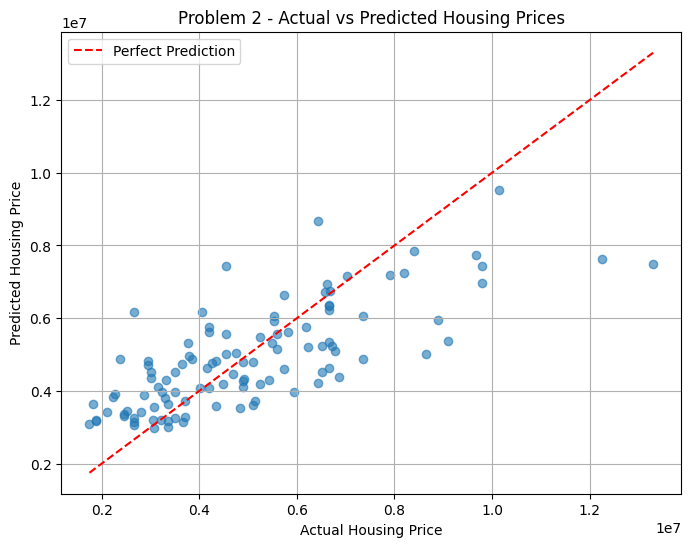

In [20]:

# Problem 2 - Actual vs predicted housing prices

best_model_2.eval()

with torch.no_grad():
    predictions_2 = best_model_2(
        X_val_tensor_2
    ).numpy().flatten() * 1_000_000

actual_2 = y_val_2.to_numpy()

plt.figure(figsize=(8, 6))

plt.scatter(actual_2, predictions_2, alpha=0.6)

minimum = min(actual_2.min(), predictions_2.min())
maximum = max(actual_2.max(), predictions_2.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Housing Price")
plt.ylabel("Predicted Housing Price")
plt.title("Problem 2 - Actual vs Predicted Housing Prices")
plt.legend()
plt.grid(True)
plt.show()


Problem 2c - Homework 2 vs Homework 5
-------------------------------------

Homework 2 - Five Features
Training Loss: 675,007,648,606.11
Validation Loss: 1,146,084,532,745.15

Homework 5 - Five Features
Training Loss: 675,004,005,432.13
Validation Loss: 1,146,360,874,176.03
Validation R²: 0.5464

Comparison
Homework 2 has the lower validation loss.
Validation Loss Difference: 276,341,430.88
Percentage Difference: 0.0241%


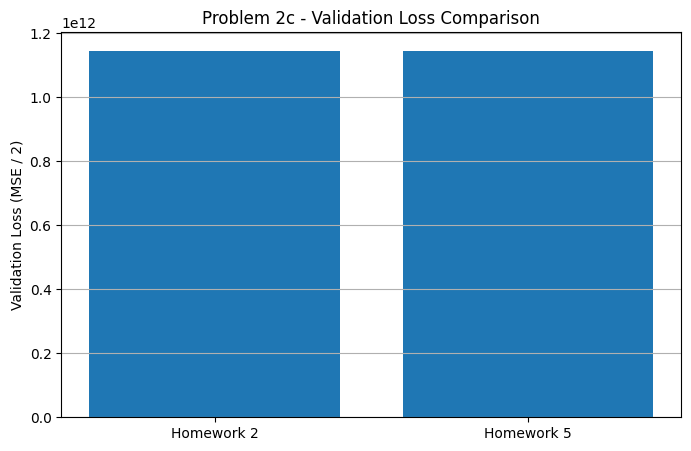

In [22]:
# Problem 2c - Comparison with Homework 2

# Homework 2 Problem 1a results
hw2_train_loss = 675007648606.11
hw2_val_loss = 1146084532745.15

# Homework 5 Problem 2 results
hw5_train_loss = 675004005432.13
hw5_val_loss = 1146360874176.03
hw5_r2 = 0.5464

print("Problem 2c - Homework 2 vs Homework 5")
print("-------------------------------------")

print("\nHomework 2 - Five Features")
print(f"Training Loss: {hw2_train_loss:,.2f}")
print(f"Validation Loss: {hw2_val_loss:,.2f}")

print("\nHomework 5 - Five Features")
print(f"Training Loss: {hw5_train_loss:,.2f}")
print(f"Validation Loss: {hw5_val_loss:,.2f}")
print(f"Validation R²: {hw5_r2:.4f}")

print("\nComparison")

if hw5_val_loss < hw2_val_loss:
    print("Homework 5 has the lower validation loss.")
else:
    print("Homework 2 has the lower validation loss.")

difference = abs(hw5_val_loss - hw2_val_loss)
percent_difference = difference / hw2_val_loss * 100

print(f"Validation Loss Difference: {difference:,.2f}")
print(f"Percentage Difference: {percent_difference:.4f}%")

# Graph comparing validation losses
plt.figure(figsize=(8, 5))

plt.bar(
    ["Homework 2", "Homework 5"],
    [hw2_val_loss, hw5_val_loss]
)

plt.ylabel("Validation Loss (MSE / 2)")
plt.title("Problem 2c - Validation Loss Comparison")
plt.grid(axis="y")
plt.show()

In [23]:

# Problem 3 - Prepare all housing features

housing_3 = housing.copy()

# Convert yes/no columns into 1 and 0
binary_columns_3 = [
    "mainroad",
    "guestroom",
    "basement",
    "hotwaterheating",
    "airconditioning",
    "prefarea"
]

for column in binary_columns_3:
    housing_3[column] = housing_3[column].map({
        "yes": 1,
        "no": 0
    })

# Convert furnishing status into numerical columns
housing_3 = pd.get_dummies(
    housing_3,
    columns=["furnishingstatus"],
    drop_first=True,
    dtype=int
)

# Use every column except price
X_3 = housing_3.drop(columns=["price"])
y_3 = housing_3["price"]

features_3 = X_3.columns.tolist()

print("Number of input features:", X_3.shape[1])
print("Input features:", features_3)
print("Total samples:", len(X_3))
print("Missing values:", X_3.isnull().sum().sum())


Number of input features: 13
Input features: ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus_semi-furnished', 'furnishingstatus_unfurnished']
Total samples: 545
Missing values: 0


In [24]:

# Problem 3 - Split and preprocess data

X_train_3, X_val_3, y_train_3, y_val_3 = train_test_split(
    X_3,
    y_3,
    test_size=0.20,
    random_state=42
)

scaler_3 = StandardScaler()

X_train_scaled_3 = scaler_3.fit_transform(X_train_3)
X_val_scaled_3 = scaler_3.transform(X_val_3)

# Represent prices in millions
y_train_scaled_3 = y_train_3.to_numpy() / 1_000_000
y_val_scaled_3 = y_val_3.to_numpy() / 1_000_000

X_train_tensor_3 = torch.tensor(
    X_train_scaled_3, dtype=torch.float32
)

X_val_tensor_3 = torch.tensor(
    X_val_scaled_3, dtype=torch.float32
)

y_train_tensor_3 = torch.tensor(
    y_train_scaled_3, dtype=torch.float32
).reshape(-1, 1)

y_val_tensor_3 = torch.tensor(
    y_val_scaled_3, dtype=torch.float32
).reshape(-1, 1)

print("Training samples:", len(X_train_tensor_3))
print("Validation samples:", len(X_val_tensor_3))
print("Number of features:", X_train_tensor_3.shape[1])


Training samples: 436
Validation samples: 109
Number of features: 13


In [25]:

# Problem 3 - Check model parameters

model_test_3 = create_housing_model(
    X_train_tensor_3.shape[1]
)

print(model_test_3)

print(
    "Number of parameters:",
    sum(p.numel() for p in model_test_3.parameters())
)


Linear(in_features=13, out_features=1, bias=True)
Number of parameters: 14


In [26]:

# Problem 3 - Train models using all features

learning_rates_3 = [0.1, 0.01, 0.001, 0.0001]
results_3 = {}

for lr in learning_rates_3:
    print(f"\nLearning Rate: {lr}")
    print("-------------------------")

    result = train_housing_model(
        num_features=X_train_tensor_3.shape[1],
        X_train=X_train_tensor_3,
        y_train=y_train_tensor_3,
        X_val=X_val_tensor_3,
        y_val=y_val_tensor_3,
        learning_rate=lr,
        epochs=5000
    )

    results_3[lr] = result

print("\nProblem 3 - Final Results")

for lr, result in results_3.items():
    print(
        f"LR {lr}: "
        f"Train Loss = {result['train_losses'][-1]:.6f}, "
        f"Val Loss = {result['val_losses'][-1]:.6f}, "
        f"Val R2 = {result['val_r2_scores'][-1]:.4f}"
    )

best_lr_3 = min(
    results_3,
    key=lambda lr: results_3[lr]["val_losses"][-1]
)

print("\nBest Learning Rate:", best_lr_3)



Learning Rate: 0.1
-------------------------
Epoch 500: Train Loss = 0.968358, Val Loss = 1.754319, Val R2 = 0.6529
Epoch 1000: Train Loss = 0.968358, Val Loss = 1.754319, Val R2 = 0.6529
Epoch 1500: Train Loss = 0.968358, Val Loss = 1.754319, Val R2 = 0.6529
Epoch 2000: Train Loss = 0.968358, Val Loss = 1.754319, Val R2 = 0.6529
Epoch 2500: Train Loss = 0.968358, Val Loss = 1.754319, Val R2 = 0.6529
Epoch 3000: Train Loss = 0.968358, Val Loss = 1.754319, Val R2 = 0.6529
Epoch 3500: Train Loss = 0.968358, Val Loss = 1.754319, Val R2 = 0.6529
Epoch 4000: Train Loss = 0.968358, Val Loss = 1.754319, Val R2 = 0.6529
Epoch 4500: Train Loss = 0.968358, Val Loss = 1.754319, Val R2 = 0.6529
Epoch 5000: Train Loss = 0.968358, Val Loss = 1.754319, Val R2 = 0.6529

Learning Rate: 0.01
-------------------------
Epoch 500: Train Loss = 0.968365, Val Loss = 1.753797, Val R2 = 0.6530
Epoch 1000: Train Loss = 0.968358, Val Loss = 1.754317, Val R2 = 0.6529
Epoch 1500: Train Loss = 0.968358, Val Loss =

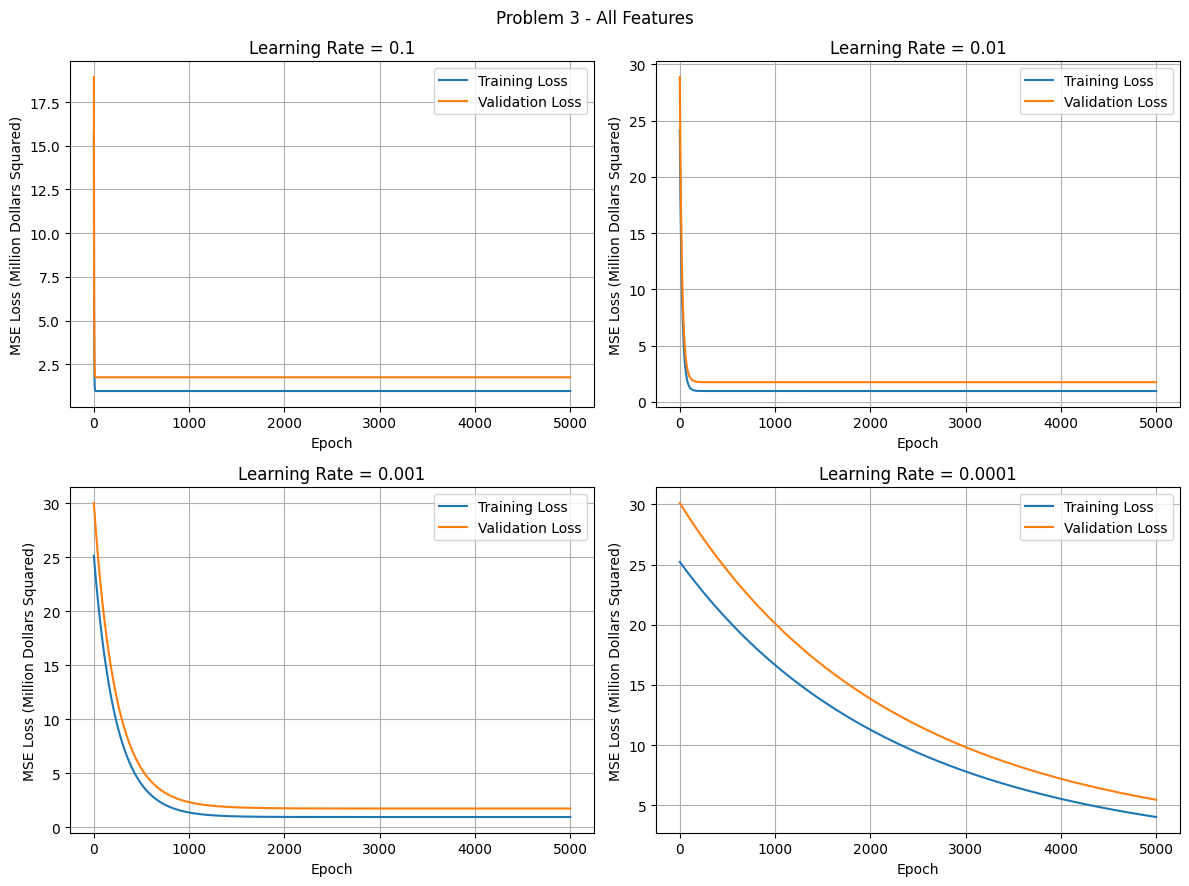

In [27]:

# Problem 3 - Training and validation loss graphs

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (lr, result) in zip(axes.flat, results_3.items()):
    ax.plot(
        range(1, 5001),
        result["train_losses"],
        label="Training Loss"
    )

    ax.plot(
        range(1, 5001),
        result["val_losses"],
        label="Validation Loss"
    )

    ax.set_title(f"Learning Rate = {lr}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE Loss (Million Dollars Squared)")
    ax.legend()
    ax.grid(True)

plt.suptitle("Problem 3 - All Features")
plt.tight_layout()
plt.show()


In [28]:

# Problem 3 - Best model parameters

best_model_3 = results_3[best_lr_3]["model"]

weights_3 = best_model_3.weight.detach().numpy().flatten()
bias_3 = best_model_3.bias.detach().item()

print("Best Learning Rate:", best_lr_3)
print("\nBest Model Parameters")

for feature, weight in zip(features_3, weights_3):
    print(f"{feature}: {weight:.6f}")

print(f"Bias: {bias_3:.6f}")

print("\nFinal Training Loss:",
      results_3[best_lr_3]["train_losses"][-1])

print("Final Validation Loss:",
      results_3[best_lr_3]["val_losses"][-1])

print("Final Validation R2:",
      results_3[best_lr_3]["val_r2_scores"][-1])


Best Learning Rate: 0.001

Best Model Parameters
area: 0.518321
bedrooms: 0.059183
bathrooms: 0.521735
stories: 0.347127
mainroad: 0.129462
guestroom: 0.089998
basement: 0.185330
hotwaterheating: 0.150093
airconditioning: 0.366031
parking: 0.192242
prefarea: 0.266627
furnishingstatus_semi-furnished: -0.062027
furnishingstatus_unfurnished: -0.191217
Bias: 4.706299

Final Training Loss: 0.9683650732040405
Final Validation Loss: 1.753793478012085
Final Validation R2: 0.6530282497406006


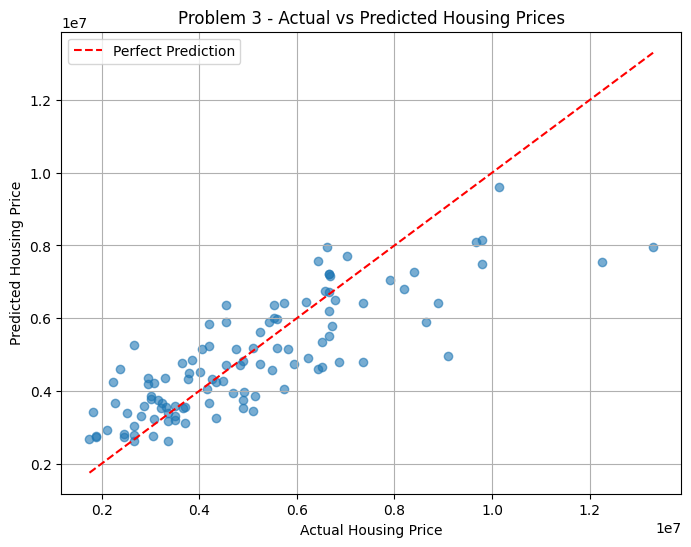

In [29]:

# Problem 3 - Actual vs predicted prices

best_model_3.eval()

with torch.no_grad():
    predictions_3 = best_model_3(
        X_val_tensor_3
    ).numpy().flatten() * 1_000_000

actual_3 = y_val_3.to_numpy()

plt.figure(figsize=(8, 6))
plt.scatter(actual_3, predictions_3, alpha=0.6)

minimum = min(actual_3.min(), predictions_3.min())
maximum = max(actual_3.max(), predictions_3.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Housing Price")
plt.ylabel("Predicted Housing Price")
plt.title("Problem 3 - Actual vs Predicted Housing Prices")
plt.legend()
plt.grid(True)
plt.show()


Problem 2 vs Problem 3
----------------------
Problem 2 - 5 Features: Val Loss = 2.292722, R2 = 0.5464
Problem 3 - All Features: Val Loss = 1.753793, R2 = 0.6530

Problem 3 performed better on validation data.


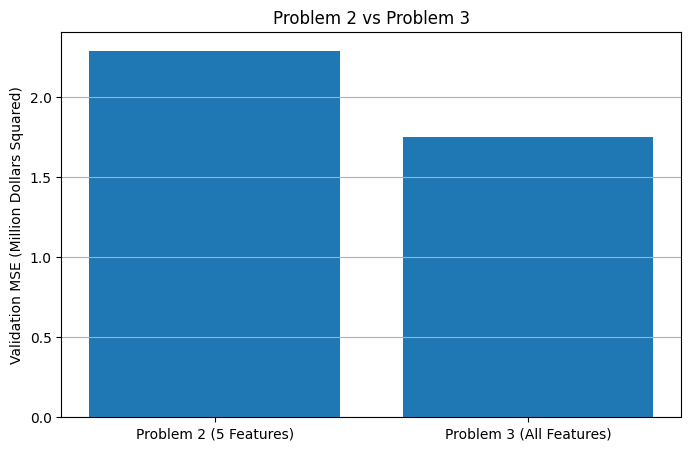

In [30]:

# Problem 3 - Compare with Problem 2

p2_val_loss = results_2[best_lr_2]["val_losses"][-1]
p3_val_loss = results_3[best_lr_3]["val_losses"][-1]

p2_r2 = results_2[best_lr_2]["val_r2_scores"][-1]
p3_r2 = results_3[best_lr_3]["val_r2_scores"][-1]

print("Problem 2 vs Problem 3")
print("----------------------")
print(f"Problem 2 - 5 Features: Val Loss = {p2_val_loss:.6f}, R2 = {p2_r2:.4f}")
print(f"Problem 3 - All Features: Val Loss = {p3_val_loss:.6f}, R2 = {p3_r2:.4f}")

if p3_val_loss < p2_val_loss:
    print("\nProblem 3 performed better on validation data.")
else:
    print("\nProblem 2 performed better on validation data.")

plt.figure(figsize=(8, 5))
plt.bar(
    ["Problem 2 (5 Features)", "Problem 3 (All Features)"],
    [p2_val_loss, p3_val_loss]
)
plt.ylabel("Validation MSE (Million Dollars Squared)")
plt.title("Problem 2 vs Problem 3")
plt.grid(axis="y")
plt.show()


Problem 3 - Homework 2 vs Homework 5
------------------------------------

Homework 2 - 11 Features
Training Loss: 496,712,536,813.65
Validation Loss: 895,037,857,176.20

Homework 5 - All Features
Training Loss: 484,182,536,602.02
Validation Loss: 876,896,739,006.04
Validation R2: 0.6530

Comparison
Homework 5 has the lower validation loss.
Validation Loss Difference: 18,141,118,170.16
Percentage Difference: 2.0269%


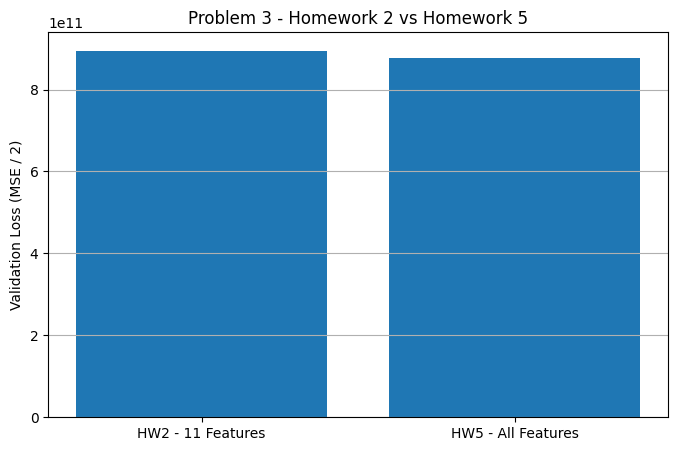

In [31]:

# Problem 3 - Comparison with Homework 2

hw2_train_loss_3 = 496712536813.65
hw2_val_loss_3 = 895037857176.20

# Convert HW5 MSE to HW2 half-MSE units
hw5_train_loss_3 = (
    results_3[best_lr_3]["train_losses"][-1]
    * (1_000_000 ** 2) / 2
)

hw5_val_loss_3 = (
    results_3[best_lr_3]["val_losses"][-1]
    * (1_000_000 ** 2) / 2
)

hw5_r2_3 = results_3[best_lr_3]["val_r2_scores"][-1]

print("Problem 3 - Homework 2 vs Homework 5")
print("------------------------------------")

print("\nHomework 2 - 11 Features")
print(f"Training Loss: {hw2_train_loss_3:,.2f}")
print(f"Validation Loss: {hw2_val_loss_3:,.2f}")

print("\nHomework 5 - All Features")
print(f"Training Loss: {hw5_train_loss_3:,.2f}")
print(f"Validation Loss: {hw5_val_loss_3:,.2f}")
print(f"Validation R2: {hw5_r2_3:.4f}")

difference_3 = abs(hw5_val_loss_3 - hw2_val_loss_3)
percent_3 = difference_3 / hw2_val_loss_3 * 100

print("\nComparison")

if hw5_val_loss_3 < hw2_val_loss_3:
    print("Homework 5 has the lower validation loss.")
else:
    print("Homework 2 has the lower validation loss.")

print(f"Validation Loss Difference: {difference_3:,.2f}")
print(f"Percentage Difference: {percent_3:.4f}%")

plt.figure(figsize=(8, 5))
plt.bar(
    ["HW2 - 11 Features", "HW5 - All Features"],
    [hw2_val_loss_3, hw5_val_loss_3]
)

plt.ylabel("Validation Loss (MSE / 2)")
plt.title("Problem 3 - Homework 2 vs Homework 5")
plt.grid(axis="y")
plt.show()


In [32]:
from google.colab import files
uploaded = files.upload()

Saving Noah_Harris_801353171_HW5.ipynb to Noah_Harris_801353171_HW5 (1).ipynb


In [35]:
!jupyter nbconvert --to html Noah_Harris_801353171_HW5.ipynb

[NbConvertApp] Converting notebook Noah_Harris_801353171_HW5.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 9 image(s).
[NbConvertApp] Writing 1015445 bytes to Noah_Harris_801353171_HW5.html


In [36]:
from google.colab import files
files.download("Noah_Harris_801353171_HW5.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>